In [47]:
import numpy as np


def anna_find_all_stable(malechoice, femalechoice, n):
    # Output list with all matchings
    res = []
    # Initialization
    unchanged = [True] * n
    marriage = [0] * n
    malecounter = [0] * n
    # Female choice transformation

    fc = np.zeros((n, n), dtype=int)
    for i in range(0, n):
        for j in range(0, n):
            fc[i][femalechoice[i][j]] = j
        fc[i][0] = n
        malecounter[i] = 0
        marriage[i] = 0

    def get_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        return(malematches)

    def print_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        print(*malematches)

    def proposal(i, malec, marriage, c):
        if i < 0:
            success = True
        elif (i == 0) or malec[i] == (n - 1) or not (unchanged[i]):  # n not (n+1), as we have n equals 5
            success = False
        else:
            c += 1
            j = malec[i]
            malec[i] = j + 1
            success = refusal(i, malechoice[i][j], malec, marriage, c)
        return success

    def refusal(i, j, malec, marriage, c):
        if fc[j][abs(marriage[j])] > fc[j][i]:
            k = marriage[j]
            marriage[j] = i
            success = proposal(k, malec, marriage, c)
        else:
            success = proposal(i, malec, marriage, c)
        return success

    def breakmariage(malecounter, marriage, i, n, count):
        malecounter_ori = malecounter.copy()
        marriage_ori = marriage.copy()
        marriage[malechoice[i][malecounter[i] - 1]] = -i
        success = proposal(i, malecounter, marriage, count)

        if not (success):
            unchanged[i] = False
            malecounter_ref = malecounter_ori.copy()
            marriage_ref = marriage_ori.copy()
            malecounter = malecounter_ref
            marriage = marriage_ref
            return malecounter, marriage

        #print_marriage(marriage)  # marriage[i] means the woman who is married to i man
        new_marriage = get_marriage(marriage)  # convert into female solution
        res.append(new_marriage)
        # establish the relationships between the original and the obtained stable matching

        for j in range(i, n):
            # if i==2 and j==2:
            #     print("This is it")
            malecounter, marriage = breakmariage(malecounter, marriage, j, n, count)

        for j in range((i + 1), n):
            unchanged[j] = True
        # return malecounter_ori, abs(marriage_ori)
        return malecounter_ori, marriage_ori

    count = 0
    for i in range(0, n):
        proposal(i, malecounter, marriage, count)
    #print_marriage(marriage)

    new_marriage = get_marriage(marriage)  # convert into female solution
    res.append(new_marriage)
    # establish the relationships between the original and the obtained stable matching

    M_optimal_marriage = marriage.copy()
    M_optimal_counter = malecounter.copy()
    for i in range(0, n):
        breakmariage(M_optimal_counter.copy(), M_optimal_marriage.copy(), i, n, count)
    return res


In [66]:
def egalitarian_cost(matching, mpref, wpref):
    n = len(matching)
    cost = 0
    for m in range(n):
        w = matching[m]
        cost += mpref[m].index(w)
        cost += wpref[w].index(m)
    return cost


In [67]:
def men_cost(matching, mpref, wpref):
    n = len(matching)
    cost = 0
    for m in range(n):
        w = matching[m]
        cost += mpref[m].index(w)
    return cost

In [68]:
def women_cost(matching, mpref, wpref):
    n = len(matching)
    cost = 0
    for m in range(n):
        w = matching[m]
        cost += wpref[w].index(m)
    return cost

In [34]:
import pandas as pd
from tqdm import tqdm
import ast
import seaborn as sns
import matplotlib.pyplot as plt

In [69]:
df = pd.read_csv("mallows_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_gain_egal.csv", index=False)


In [70]:
men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_gain_egal.csv", index=False)


In [71]:
cost_diffs = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    
    stable = anna_find_all_stable(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, mpref, wpref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, mpref, wpref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, mpref, wpref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("mallows_gain_egal.csv", index=False)

100%|█████████████████████████████████████████████████████████████████████████████| 3600/3600 [00:06<00:00, 597.67it/s]


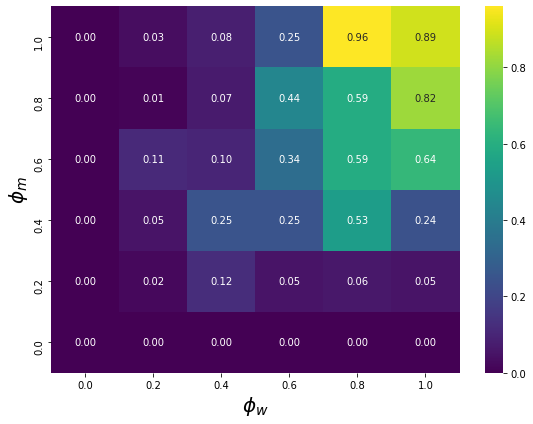

In [73]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
#plt.title("Mallows")
plt.xlabel("$\phi_w$", fontsize = 20)
plt.ylabel("$\phi_m$", fontsize = 20)
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("trunc_egal_mall.pdf", format="pdf")
plt.show()


In [74]:
df = pd.read_csv("mallows_euclidean_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)

cost_diffs = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    
    stable = anna_find_all_stable(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, mpref, wpref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, mpref, wpref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, mpref, wpref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)

100%|█████████████████████████████████████████████████████████████████████████████| 3600/3600 [00:08<00:00, 405.16it/s]


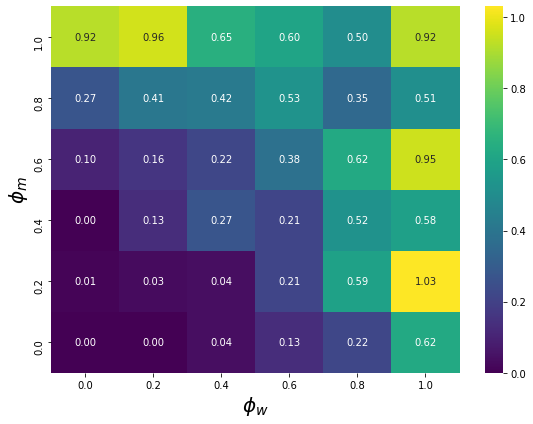

In [75]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
#plt.title("Mallows")
plt.xlabel("$\phi_w$", fontsize = 20)
plt.ylabel("$\phi_m$", fontsize = 20)
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("trunc_egal_mall_euc.pdf", format="pdf")
plt.show()


In [76]:
df = pd.read_csv("mallows_MA_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_MA_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_MA_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_MA_gain_egal.csv", index=False)

cost_diffs = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    
    stable = anna_find_all_stable(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, mpref, wpref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, mpref, wpref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, mpref, wpref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("mallows_MA_gain_egal.csv", index=False)

100%|█████████████████████████████████████████████████████████████████████████████| 3600/3600 [00:09<00:00, 396.36it/s]


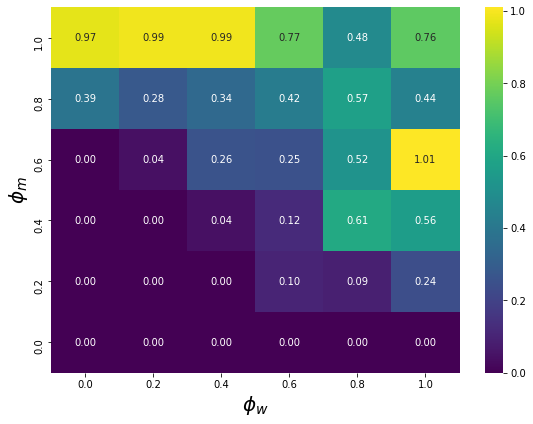

In [77]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MA_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
#plt.title("Mallows")
plt.xlabel("$\phi_w$", fontsize = 20)
plt.ylabel("$\phi_m$", fontsize = 20)
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("trunc_egal_mall_MA.pdf", format="pdf")
plt.show()


In [78]:
df = pd.read_csv("mallows_MD_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_MD_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_MD_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_MD_gain_egal.csv", index=False)

cost_diffs = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    
    stable = anna_find_all_stable(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, mpref, wpref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, mpref, wpref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, mpref, wpref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("mallows_MD_gain_egal.csv", index=False)

100%|█████████████████████████████████████████████████████████████████████████████| 3600/3600 [00:11<00:00, 309.54it/s]


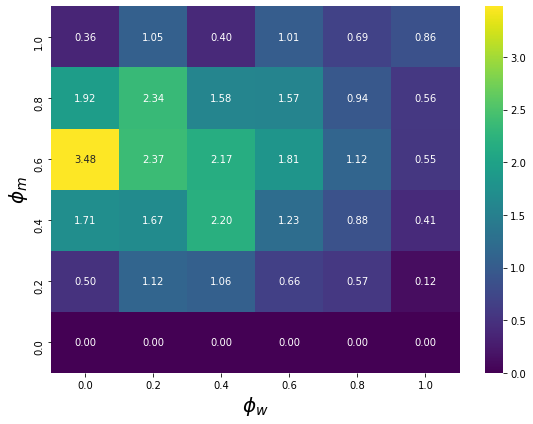

In [79]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MD_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
#plt.title("Mallows")
plt.xlabel("$\phi_w$", fontsize = 20)
plt.ylabel("$\phi_m$", fontsize = 20)
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("trunc_egal_mall_MD.pdf", format="pdf")
plt.show()


In [80]:
df = pd.read_csv("reverse_euclidean_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)

cost_diffs = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    
    stable = anna_find_all_stable(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, mpref, wpref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, mpref, wpref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, mpref, wpref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)

100%|█████████████████████████████████████████████████████████████████████████████| 3000/3000 [00:07<00:00, 378.75it/s]


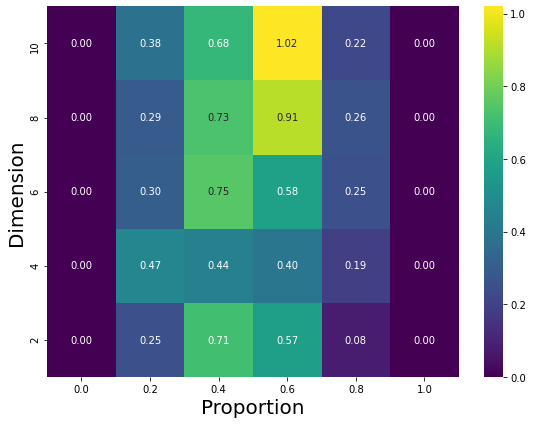

In [82]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("reverse_euclidean_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "proportion"])["trunc_egal"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="proportion", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
#plt.title("Mallows")
plt.xlabel("Proportion", fontsize = 20)
plt.ylabel("Dimension", fontsize = 20)
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("trunc_egal_rev_euc.pdf", format="pdf")
plt.show()


In [83]:
df = pd.read_csv("expectations_euclidean_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("expectations_euclidean_gain.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("expectations_euclidean_gain.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, mpref, wpref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("expectations_euclidean_gain.csv", index=False)

cost_diffs = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    
    stable = anna_find_all_stable(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, mpref, wpref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, mpref, wpref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, mpref, wpref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("expectations_euclidean_gain.csv", index=False)

100%|█████████████████████████████████████████████████████████████████████████████| 3000/3000 [00:03<00:00, 752.85it/s]


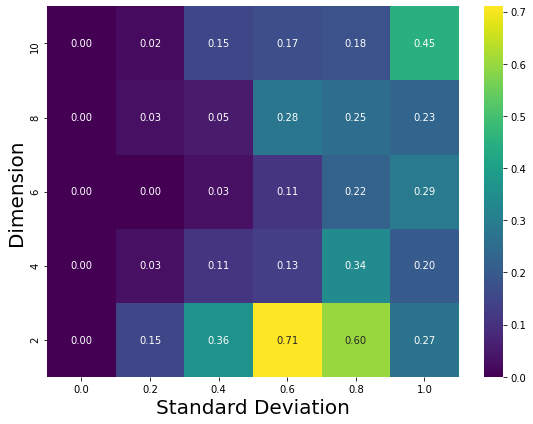

In [84]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_gain.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["trunc_egal"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
#plt.title("Mallows")
plt.xlabel("Standard Deviation", fontsize = 20)
plt.ylabel("Dimension", fontsize = 20)
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("trunc_egal_exp_euc.pdf", format="pdf")
plt.show()
